# Single-reference availability for spatial transcriptomics

This notebook uses `harmonized_metadata.csv` from `HarmonizeDatabases.ipynb` to quantify the best available single sc/snRNA-seq reference for each spatial transcriptomics dataset. The score intentionally ignores cell type overlap and uses only organism, harmonized tissue, disease, reference quality, and same-study metadata.

In [1]:
from ast import literal_eval
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path(".")
if not (DATA_DIR / "harmonized_metadata.csv").exists():
    DATA_DIR = Path("data_availability_quantification")
if str(DATA_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(DATA_DIR.resolve()))

from single_reference_availability import run_quantification


INPUT_PATH = DATA_DIR / "harmonized_metadata.csv"
TOP_SCORES_PATH = DATA_DIR / "single_reference_scores.csv"
BEST_PATH = DATA_DIR / "single_reference_best.csv"
SUMMARY_PATH = DATA_DIR / "single_reference_summary.csv"


## Run quantification

Outputs are written as CSVs so downstream analyses do not need to rerun the scoring step.

In [2]:
reference_scores, best_refs, summary = run_quantification(
    input_path=INPUT_PATH,
    top_scores_path=TOP_SCORES_PATH,
    best_path=BEST_PATH,
    summary_path=SUMMARY_PATH,
    top_k=10,
    require_same_species=False,
)

summary

,metric,value
0,n_spatial_datasets,7659.000000
1,n_reference_candidates,2096.000000
2,n_spatial_with_score_gt_0,5362.000000
3,n_spatial_with_same_tissue_reference,4875.000000
4,n_spatial_without_same_tissue_reference,2784.000000
5,fraction_spatial_without_same_tissue_reference,0.363494
6,fraction_spatial_with_score_gt_0,0.700091
7,fraction_spatial_with_score_ge_0.35,0.700091
8,fraction_spatial_with_score_ge_0.60,0.646690
9,fraction_spatial_with_score_ge_0.80,0.301345


,spatial_dataset_id,spatial_dataset_title,spatial_source_database,spatial_collection_id,spatial_collection_name,spatial_dataset_type,spatial_assays,spatial_organisms,spatial_tissue_general,spatial_tissues,...,has_same_tissue_match,has_tissue_match,tissue_match_level,missing_same_tissue_reference,tissue_score,disease_score,quality_score,same_study_score,ref_n_cells,ref_n_donors
0,0069d283c84d06b656142a607e5d06d4,GeoMx (NGS) data from the placenta of a 25-yea...,hubmap,1fe64d24-c870-11eb-9a03-a9c8d5e16226,TMC - University of California San Diego focus...,GeoMx (NGS),[GeoMx (NGS)],[homo_sapiens],[placenta],[placenta],...,True,True,specific,False,1.0,1.00,1.0,0.0,325665.0,34.0
1,00803fcc973d6a8a331b5d0a7dbce8c1,GeoMx (NGS) data from the placenta of a 29-yea...,hubmap,1fe64d24-c870-11eb-9a03-a9c8d5e16226,TMC - University of California San Diego focus...,GeoMx (NGS),[GeoMx (NGS)],[homo_sapiens],[placenta],[placenta],...,True,True,specific,False,1.0,1.00,1.0,0.0,325665.0,34.0
2,00c30e02521ac68f41b57cd9c3f17582,GeoMx (NGS) data from the placenta of a 36-yea...,hubmap,1fe64d24-c870-11eb-9a03-a9c8d5e16226,TMC - University of California San Diego focus...,GeoMx (NGS),[GeoMx (NGS)],[homo_sapiens],[placenta],[placenta],...,True,True,specific,False,1.0,1.00,1.0,0.0,325665.0,34.0
3,01209d6b5ef07cf28dbc3d41f53af104,GeoMx (NGS) data from the placenta of a 25-yea...,hubmap,1fe64d24-c870-11eb-9a03-a9c8d5e16226,TMC - University of California San Diego focus...,GeoMx (NGS),[GeoMx (NGS)],[homo_sapiens],[placenta],[placenta],...,True,True,specific,False,1.0,1.00,1.0,0.0,325665.0,34.0
4,0133be5ebc81da3a22059122169287f4,Visium (no probes) data from the fallopian tub...,hubmap,69cb89c4-c870-11eb-b360-4dfdb5d10392,TMC - University of Pennsylvania,Visium (no probes),[Visium (no probes)],[homo_sapiens],[female reproductive system],[fallopian tube],...,True,True,specific,False,1.0,1.00,0.0,1.0,2275.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7653,museum_st_ff98a7ed2241,Spatial transcriptome sequencing of FFPE tissu...,museum_of_spatial_transcriptomics,GSE156862,Spatial transcriptome sequencing of FFPE tissu...,DBiT-seq,[DBiT-seq],[mus_musculus],[vasculature],"[aorta (ffpe), aorta]",...,True,True,specific,False,1.0,1.00,1.0,0.0,110824.0,21.0
7654,museum_st_ffcac0e3f8a7,Spatial multiomics reveal intratumoral immune ...,museum_of_spatial_transcriptomics,39400127.0,Spatial multiomics reveal intratumoral immune ...,GeoMX WTA,[GeoMX WTA],[homo_sapiens],[brain],"[lung cancer brain metastases, brain]",...,True,True,specific,False,1.0,0.35,1.0,0.0,1920454.0,55.0
7655,museum_st_ffd6d6fda9aa,Metastatic Clones in HPV-related Cancer of the...,museum_of_spatial_transcriptomics,NaN,Metastatic Clones in HPV-related Cancer of the...,Visium,[Visium],[homo_sapiens],[lymph node],"[lymph node metastasis, lymph node]",...,True,True,specific,False,1.0,0.35,1.0,0.0,147137.0,42.0
7656,museum_st_ffe01a933e00,Cell-type-specific transposable element demeth...,museum_of_spatial_transcriptomics,NaN,Cell-type-specific transposable element demeth...,MERFISH,[MERFISH],[mus_musculus],[brain],"[coronal brain sections, brain]",...,True,True,specific,False,1.0,1.00,1.0,0.0,147137.0,42.0


In [7]:
image_based_transcriptomics = [
    "CosMX",
    "Xenium",
    "MERFISH",
    "seqFISH",
    "seqFISH+",
    "osmFISH",
    "smFISH",
    "bDNA-smFISH",
    "bDNA-MERFISH",
    "HCR-seqFISH",
    "ExM-MERFISH",
    "split-FISH",
    "par-seqFISH",
    "corrFISH",
    "SRM seqFISH",
    "iceFISH",
    "C-FISH",
    "RNAscope",
    "Molecular Cartography",
    "coppaFISH",
    "HybISS",
    "HybRISS",
    "ISS",
    "IISS",
    "FISSEQ",
    "STARmap",
    "STARmap PLUS",
    "Deep-STARmap",
    "ExSeq",
    "EASI-FISH",
    "SCRINSHOT",
    "CISI",
    "MOSAICA",
    "PHYTOMap",
    "ARTseq-FISH",
    "clampFISH 2.0",
    "mFISH3D",
    "Spectrum-FISH",
    "USeqFISH",
    "FISHnCHIPs",
    "DART-FISH",
    "Perturb-FISH",
    "cycleHCR",
    "bacterial-MERFISH",
    "weMERFISH",
    "hamFISH",
    "3DEEP-FISH",
    "HiPlex FISH",
    "ATLAS",
    "RCA-MERFISH",
    "PRISM",
    "RAM-FISH",
    "GenePS",
    "RAEFISH",
    "BCR-MERFISH",
    "split-roll FISH",
    "TEMPOmap",
    "RNAsky",
    "PerturbView",
    "SWITCH-seq",
    "combFISH",
    "Cartana",
]

In [13]:
reference_scores = reference_scores[(reference_scores['spatial_dataset_type'].isin(image_based_transcriptomics))&(reference_scores['spatial_organisms'].astype(str)!='[]')]
best_refs = best_refs[(best_refs['spatial_dataset_type'].isin(image_based_transcriptomics))&
                      (best_refs['spatial_organisms'].astype(str)!='[]')&
                      (best_refs['spatial_tissues'].astype(str)!='[]')]

In [24]:
best_refs[(best_refs['spatial_tissues'].astype(str)!='[]')].columns

Index(['spatial_dataset_id', 'spatial_dataset_title',
       'spatial_source_database', 'spatial_collection_id',
       'spatial_collection_name', 'spatial_dataset_type', 'spatial_assays',
       'spatial_organisms', 'spatial_tissue_general', 'spatial_tissues',
       'spatial_diseases', 'ref_dataset_id', 'ref_dataset_title',
       'ref_source_database', 'ref_collection_id', 'ref_collection_name',
       'ref_dataset_type', 'ref_assays', 'ref_organisms', 'ref_tissue_general',
       'ref_tissues', 'ref_diseases', 'score', 'tier', 'has_same_tissue_match',
       'has_tissue_match', 'tissue_match_level',
       'missing_same_tissue_reference', 'tissue_score', 'disease_score',
       'quality_score', 'same_study_score', 'ref_n_cells', 'ref_n_donors',
       'ref_organism', 'spatial_organism'],
      dtype='object')

<Axes: xlabel='score', ylabel='Count'>

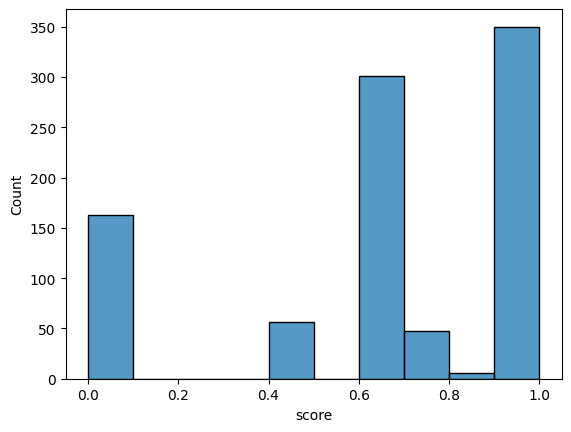

In [25]:
import seaborn as sns
import numpy as np
reference_scores['ref_organism'] = reference_scores['ref_organisms'].apply(lambda x: x[0] if isinstance(x,list) else 'none' )
reference_scores['spatial_organism'] = reference_scores['spatial_organisms'].apply(lambda x: x[0] if (isinstance(x,list) and len(x)>0) else 'none')
best_refs['ref_organism'] = best_refs['ref_organisms'].apply(lambda x: x[0] if isinstance(x,list) else 'none' )
best_refs['spatial_organism'] = best_refs['spatial_organisms'].apply(lambda x: x[0] if (isinstance(x,list) and len(x) > 0) else 'none' )
sns.histplot(data=best_refs,x='score',bins=np.arange(0,1.01,0.1))#,hue='ref_organism')

In [27]:
best_refs[(best_refs['score']<0.2)]['spatial_organisms'].astype(str)

770               ['homo_sapiens']
821          ['triticum_aestivum']
836               ['oryza_sativa']
839       ['arabidopsis_thaliana']
853       ['arabidopsis_thaliana']
                   ...            
7527    ['pseudomonas_aeruginosa']
7568              ['homo_sapiens']
7574             ['gallus_gallus']
7599              ['homo_sapiens']
7651             ['gallus_gallus']
Name: spatial_organisms, Length: 163, dtype: object

In [23]:
best_refs[(best_refs['score']<0.2)&(best_refs['spatial_organisms'].astype(str).str.contains('homo_sapiens'))]

,spatial_dataset_id,spatial_dataset_title,spatial_source_database,spatial_collection_id,spatial_collection_name,spatial_dataset_type,spatial_assays,spatial_organisms,spatial_tissue_general,spatial_tissues,...,tissue_match_level,missing_same_tissue_reference,tissue_score,disease_score,quality_score,same_study_score,ref_n_cells,ref_n_donors,ref_organism,spatial_organism
770,museum_st_03fe6dd39cbd,Systematic benchmarking of imaging spatial tra...,museum_of_spatial_transcriptomics,41266321.0,Systematic benchmarking of imaging spatial tra...,CosMX,[CosMX],[homo_sapiens],[ffpe tmas],[ffpe tmas],...,none,True,0.0,0.0,0.0,0.0,NaN,NaN,none,homo_sapiens
891,museum_st_088f9e26e917,Localization and abundance analysis of human l...,museum_of_spatial_transcriptomics,25630241.0,Localization and abundance analysis of human l...,smFISH,[smFISH],[homo_sapiens],[hela],[hela],...,none,True,0.0,0.0,0.0,0.0,NaN,NaN,none,homo_sapiens
1067,museum_st_0f195574e740,Inhibiting EZH2 complements steroid effects in...,museum_of_spatial_transcriptomics,NaN,Inhibiting EZH2 complements steroid effects in...,MERFISH,[MERFISH],[homo_sapiens],[muscle],"[muscle (control), skeletal muscle]",...,none,True,0.0,0.0,0.0,0.0,NaN,NaN,none,homo_sapiens
1095,museum_st_10543570a1ef,Multiplexed detection of RNA using MERFISH and...,museum_of_spatial_transcriptomics,31118500.0,Multiplexed detection of RNA using MERFISH and...,bDNA-MERFISH,[bDNA-MERFISH],[homo_sapiens],[u-2 os],[u-2 os],...,none,True,0.0,0.0,0.0,0.0,NaN,NaN,none,homo_sapiens
1260,museum_st_16d38ce44a9a,Highly resolved spatial transcriptomics for de...,museum_of_spatial_transcriptomics,NaN,Highly resolved spatial transcriptomics for de...,Molecular Cartography,[Molecular Cartography],[homo_sapiens],[hela cells],[hela cells],...,none,True,0.0,0.0,0.0,0.0,NaN,NaN,none,homo_sapiens
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6759,museum_st_df12b94a4987,"Spatio-temporal, optogenetic control of gene e...",museum_of_spatial_transcriptomics,NaN,"Spatio-temporal, optogenetic control of gene e...",Molecular Cartography,[Molecular Cartography],[homo_sapiens],[neural tube organoid model with optogenetic s...,[neural tube organoid model with optogenetic s...,...,none,True,0.0,0.0,0.0,0.0,NaN,NaN,none,homo_sapiens
7172,museum_st_ee4b11be1a3b,High-performance multiplexed fluorescence in s...,museum_of_spatial_transcriptomics,27911841.0,High-performance multiplexed fluorescence in s...,MERFISH,[MERFISH],[homo_sapiens],[u-2 os],[u-2 os],...,none,True,0.0,0.0,0.0,0.0,NaN,NaN,none,homo_sapiens
7289,museum_st_f24051133e55,Genital herpes shedding episodes associate wit...,museum_of_spatial_transcriptomics,NaN,Genital herpes shedding episodes associate wit...,Xenium,[Xenium],[homo_sapiens],"[vagina, vagina tract (hsv-2 seropositive)]","[vagina tract (hsv-2 seropositive), vagina]",...,none,True,0.0,0.0,0.0,0.0,NaN,NaN,none,homo_sapiens
7568,museum_st_fcbe6dbaa9b1,Multiplexed imaging of high-density libraries ...,museum_of_spatial_transcriptomics,29555914.0,Multiplexed imaging of high-density libraries ...,MERFISH,[MERFISH],[homo_sapiens],[u-2 os],[u-2 os],...,none,True,0.0,0.0,0.0,0.0,NaN,NaN,none,homo_sapiens


In [39]:
best_refs

,spatial_dataset_id,spatial_dataset_title,spatial_source_database,spatial_collection_id,spatial_collection_name,spatial_dataset_type,spatial_assays,spatial_organisms,spatial_tissue_general,spatial_tissues,...,tissue_match_level,missing_same_tissue_reference,tissue_score,disease_score,quality_score,same_study_score,ref_n_cells,ref_n_donors,ref_organism,spatial_organism
54,149eea2020a082ea9dd5683bdaca67c9,seqFISH data from the spleen of a 62-year-old ...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[spleen],[spleen],...,specific,False,1.0,1.00,0.160580,0.0,15323.0,1.0,homo_sapiens,homo_sapiens
239,56fd9c83a140673c1b259612a91f2bb0,seqFISH data from the small intestine of a 62-...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[intestine],[small intestine],...,specific,False,1.0,1.00,0.153222,0.0,14850.0,1.0,homo_sapiens,homo_sapiens
383,8f0becaf2d0eea9df67e45b8d66d69ac,seqFISH data from the heart of a 44-year-old b...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[heart],[heart],...,specific,False,1.0,1.00,0.700000,1.0,270000.0,1.0,homo_sapiens,homo_sapiens
385,9046d09943f6a10b70544822de1d5752,seqFISH data from the spleen of a 62-year-old ...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[spleen],[spleen],...,specific,False,1.0,1.00,0.160580,0.0,15323.0,1.0,homo_sapiens,homo_sapiens
511,bf447e198a99cb780d93437f05b2452d,seqFISH data from the small intestine of a 62-...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[intestine],[small intestine],...,specific,False,1.0,1.00,0.153222,0.0,14850.0,1.0,homo_sapiens,homo_sapiens
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7607,museum_st_fddc900e748a,Spatial and temporal profiling of the compleme...,museum_of_spatial_transcriptomics,NaN,Spatial and temporal profiling of the compleme...,MERFISH,[MERFISH],[mus_musculus],[brain],"[saggital brain sections, brain]",...,specific,False,1.0,1.00,1.000000,0.0,147137.0,42.0,homo_sapiens,mus_musculus
7637,museum_st_fefe6384baa7,Tertiary lymphoid structure as a therapeutic t...,museum_of_spatial_transcriptomics,NaN,Tertiary lymphoid structure as a therapeutic t...,Xenium,[Xenium],[homo_sapiens],[colon],"[colon, crohn's disease, ifx treated, colon]",...,specific,False,1.0,0.35,1.000000,0.0,594283.0,137.0,homo_sapiens,homo_sapiens
7644,museum_st_ff575d92547b,Medulloblastoma oncogene aberrations are not i...,museum_of_spatial_transcriptomics,NaN,Medulloblastoma oncogene aberrations are not i...,Molecular Cartography,[Molecular Cartography],[homo_sapiens],"[brain, medullablastoma (relapse)]","[medullablastoma (relapse), brain]",...,specific,False,1.0,0.35,1.000000,0.0,1920454.0,55.0,homo_sapiens,homo_sapiens
7651,museum_st_ff8cb9a7a224,"Open-source, high-throughput targeted in-situ ...",museum_of_spatial_transcriptomics,NaN,"Open-source, high-throughput targeted in-situ ...",ISS,[ISS],[gallus_gallus],[optic tectum],[optic tectum],...,none,True,0.0,0.00,0.000000,0.0,NaN,NaN,none,gallus_gallus


In [40]:
best_refs

,spatial_dataset_id,spatial_dataset_title,spatial_source_database,spatial_collection_id,spatial_collection_name,spatial_dataset_type,spatial_assays,spatial_organisms,spatial_tissue_general,spatial_tissues,...,tissue_match_level,missing_same_tissue_reference,tissue_score,disease_score,quality_score,same_study_score,ref_n_cells,ref_n_donors,ref_organism,spatial_organism
54,149eea2020a082ea9dd5683bdaca67c9,seqFISH data from the spleen of a 62-year-old ...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[spleen],[spleen],...,specific,False,1.0,1.00,0.160580,0.0,15323.0,1.0,homo_sapiens,homo_sapiens
239,56fd9c83a140673c1b259612a91f2bb0,seqFISH data from the small intestine of a 62-...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[intestine],[small intestine],...,specific,False,1.0,1.00,0.153222,0.0,14850.0,1.0,homo_sapiens,homo_sapiens
383,8f0becaf2d0eea9df67e45b8d66d69ac,seqFISH data from the heart of a 44-year-old b...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[heart],[heart],...,specific,False,1.0,1.00,0.700000,1.0,270000.0,1.0,homo_sapiens,homo_sapiens
385,9046d09943f6a10b70544822de1d5752,seqFISH data from the spleen of a 62-year-old ...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[spleen],[spleen],...,specific,False,1.0,1.00,0.160580,0.0,15323.0,1.0,homo_sapiens,homo_sapiens
511,bf447e198a99cb780d93437f05b2452d,seqFISH data from the small intestine of a 62-...,hubmap,308f5ffc-ed43-11e8-b56a-0e8017bdda58,California Institute of Technology TMC,seqFISH,[seqFISH],[homo_sapiens],[intestine],[small intestine],...,specific,False,1.0,1.00,0.153222,0.0,14850.0,1.0,homo_sapiens,homo_sapiens
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7607,museum_st_fddc900e748a,Spatial and temporal profiling of the compleme...,museum_of_spatial_transcriptomics,NaN,Spatial and temporal profiling of the compleme...,MERFISH,[MERFISH],[mus_musculus],[brain],"[saggital brain sections, brain]",...,specific,False,1.0,1.00,1.000000,0.0,147137.0,42.0,homo_sapiens,mus_musculus
7637,museum_st_fefe6384baa7,Tertiary lymphoid structure as a therapeutic t...,museum_of_spatial_transcriptomics,NaN,Tertiary lymphoid structure as a therapeutic t...,Xenium,[Xenium],[homo_sapiens],[colon],"[colon, crohn's disease, ifx treated, colon]",...,specific,False,1.0,0.35,1.000000,0.0,594283.0,137.0,homo_sapiens,homo_sapiens
7644,museum_st_ff575d92547b,Medulloblastoma oncogene aberrations are not i...,museum_of_spatial_transcriptomics,NaN,Medulloblastoma oncogene aberrations are not i...,Molecular Cartography,[Molecular Cartography],[homo_sapiens],"[brain, medullablastoma (relapse)]","[medullablastoma (relapse), brain]",...,specific,False,1.0,0.35,1.000000,0.0,1920454.0,55.0,homo_sapiens,homo_sapiens
7651,museum_st_ff8cb9a7a224,"Open-source, high-throughput targeted in-situ ...",museum_of_spatial_transcriptomics,NaN,"Open-source, high-throughput targeted in-situ ...",ISS,[ISS],[gallus_gallus],[optic tectum],[optic tectum],...,none,True,0.0,0.00,0.000000,0.0,NaN,NaN,none,gallus_gallus


In [41]:
best_refs["tier"].value_counts(dropna=False)

tier
A: strong matched reference           356
B: usable reference                   348
E: no metadata-supported reference    179
C: partial reference                   56
Name: count, dtype: int64

## Availability plots

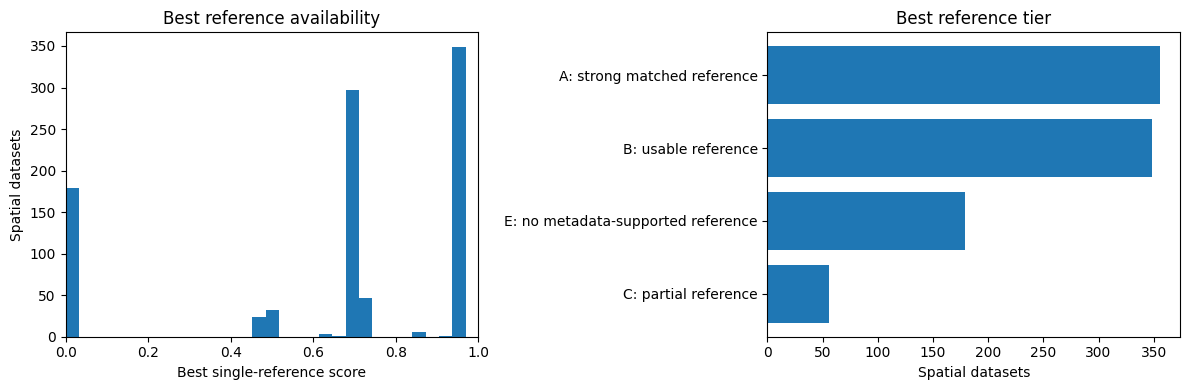

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(best_refs["score"].dropna(), bins=30)
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("Best single-reference score")
axes[0].set_ylabel("Spatial datasets")
axes[0].set_title("Best reference availability")

tier_counts = best_refs["tier"].value_counts()
axes[1].barh(tier_counts.index[::-1], tier_counts.values[::-1])
axes[1].set_xlabel("Spatial datasets")
axes[1].set_title("Best reference tier")

plt.tight_layout()
plt.show()


## Spatial Organism Availability

Mean best-reference score by spatial dataset organism. This includes organisms with no matching reference, which remain in `best_refs` with score `0`.


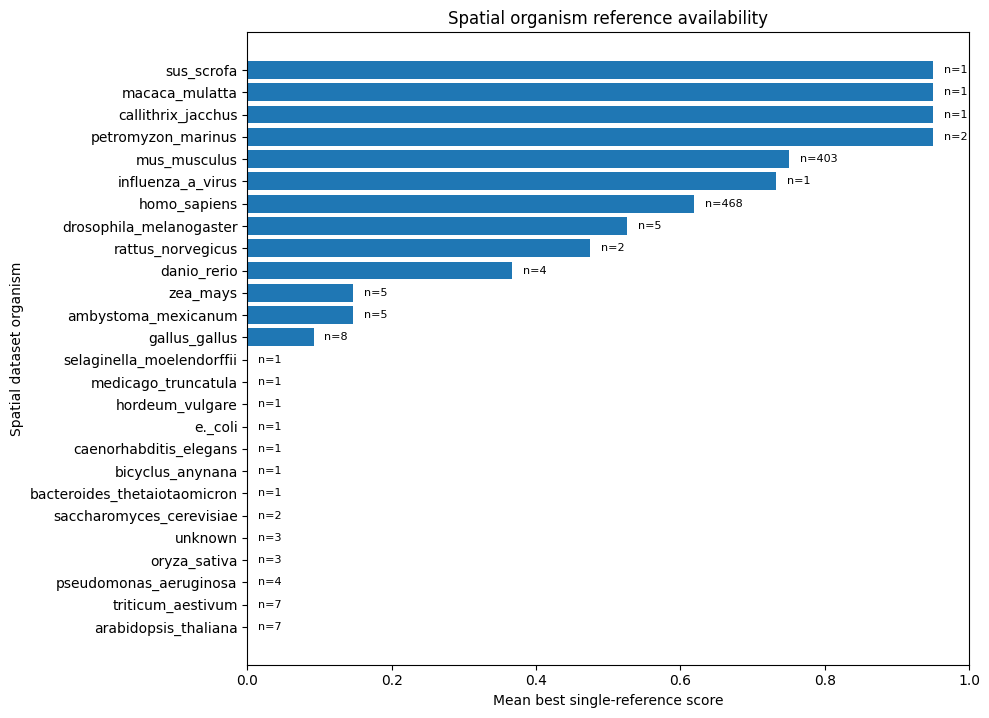

,spatial_organism,mean_score,median_score,n_spatial_datasets,n_with_reference
10,homo_sapiens,0.619570,0.685357,468,393
15,mus_musculus,0.751107,0.950000,403,352
9,gallus_gallus,0.091607,0.000000,8,1
1,arabidopsis_thaliana,0.000000,0.000000,7,0
23,triticum_aestivum,0.000000,0.000000,7,0
0,ambystoma_mexicanum,0.146571,0.000000,5,1
7,drosophila_melanogaster,0.526571,0.732857,5,3
25,zea_mays,0.146571,0.000000,5,1
18,pseudomonas_aeruginosa,0.000000,0.000000,4,0
6,danio_rerio,0.366429,0.366429,4,2


In [43]:
def first_label(value, missing="unknown"):
    if isinstance(value, list):
        return value[0] if value else missing
    if pd.isna(value):
        return missing
    text = str(value).strip()
    if not text or text.lower() in {"nan", "none", "null"}:
        return missing
    if text.startswith("[") and text.endswith("]"):
        try:
            parsed = literal_eval(text)
        except (ValueError, SyntaxError):
            parsed = []
        if isinstance(parsed, list) and parsed:
            return str(parsed[0])
    return text

organism_scores = (
    best_refs
    .assign(spatial_organism=lambda df: df["spatial_organisms"].apply(first_label))
    .groupby("spatial_organism", dropna=False)
    .agg(
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        n_spatial_datasets=("spatial_dataset_id", "nunique"),
        n_with_reference=("score", lambda x: (x > 0).sum()),
    )
    .reset_index()
    .sort_values(["mean_score", "n_spatial_datasets"], ascending=[True, False])
)

fig_height = max(5, 0.28 * len(organism_scores))
fig, ax = plt.subplots(figsize=(10, fig_height))
ax.barh(organism_scores["spatial_organism"], organism_scores["mean_score"])
ax.set_xlim(0, 1)
ax.set_xlabel("Mean best single-reference score")
ax.set_ylabel("Spatial dataset organism")
ax.set_title("Spatial organism reference availability")

for y, (_, row) in enumerate(organism_scores.iterrows()):
    ax.text(
        min(row["mean_score"] + 0.015, 0.98),
        y,
        f"n={int(row['n_spatial_datasets'])}",
        va="center",
        fontsize=8,
    )

plt.tight_layout()
plt.show()

organism_scores.sort_values("n_spatial_datasets", ascending=False).head(30)


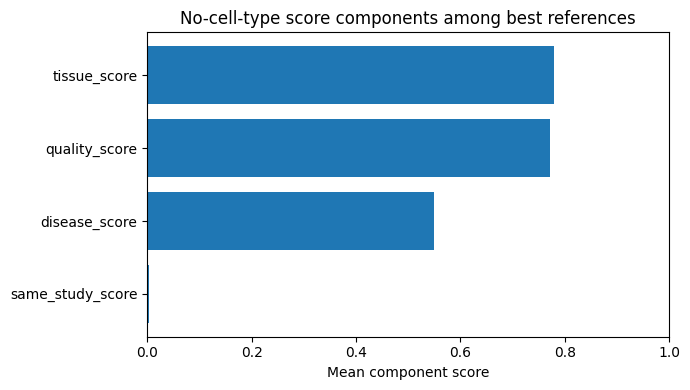

In [44]:
component_cols = ["tissue_score", "disease_score", "quality_score", "same_study_score"]
component_means = best_refs[component_cols].mean().sort_values()

plt.figure(figsize=(7, 4))
plt.barh(component_means.index, component_means.values)
plt.xlim(0, 1)
plt.xlabel("Mean component score")
plt.title("No-cell-type score components among best references")
plt.tight_layout()
plt.show()


## Best-reference table

In [45]:
display_cols = [
    "spatial_source_database",
    "spatial_dataset_id",
    "spatial_dataset_title",
    "spatial_dataset_type",
    "spatial_tissue_general",
    "spatial_tissues",
    "ref_source_database",
    "ref_dataset_id",
    "ref_dataset_title",
    "ref_dataset_type",
    "score",
    "tier",
    "has_same_tissue_match",
    "has_tissue_match",
    "tissue_match_level",
    "missing_same_tissue_reference",
    "tissue_score",
    "disease_score",
    "quality_score",
    "same_study_score",
]

best_refs[display_cols].sort_values("score", ascending=False).head(30)


,spatial_source_database,spatial_dataset_id,spatial_dataset_title,spatial_dataset_type,spatial_tissue_general,spatial_tissues,ref_source_database,ref_dataset_id,ref_dataset_title,ref_dataset_type,score,tier,has_same_tissue_match,has_tissue_match,tissue_match_level,missing_same_tissue_reference,tissue_score,disease_score,quality_score,same_study_score
383,hubmap,8f0becaf2d0eea9df67e45b8d66d69ac,seqFISH data from the heart of a 44-year-old b...,seqFISH,[heart],[heart],hubmap,fdf26c991b398a26be1354543e54af23,RNAseq data from the heart of a 43-year-old wh...,RNAseq,0.97,A: strong matched reference,True,True,specific,False,1.0,1.0,0.7,1.0
612,hubmap,eaad5ed4b3aa2186bd87e05ff28b593e,seqFISH data from the heart of a 44-year-old b...,seqFISH,[heart],[heart],hubmap,fdf26c991b398a26be1354543e54af23,RNAseq data from the heart of a 43-year-old wh...,RNAseq,0.97,A: strong matched reference,True,True,specific,False,1.0,1.0,0.7,1.0
528,hubmap,c6a254b2dc2ed46b002500ade163a7cc,seqFISH data from the heart of a 44-year-old b...,seqFISH,[heart],[heart],hubmap,fdf26c991b398a26be1354543e54af23,RNAseq data from the heart of a 43-year-old wh...,RNAseq,0.97,A: strong matched reference,True,True,specific,False,1.0,1.0,0.7,1.0
6771,museum_of_spatial_transcriptomics,museum_st_df6df45125f9,Rigor and Reproducibility of Spatial Transcrip...,CosMX,[kidney],"[uninvolved kidney, kidney]",cellxgene,98e5ea9f-16d6-47ec-a529-686e76515e39,All - A single-cell transcriptomic atlas chara...,NaN,0.95,A: strong matched reference,True,True,specific,False,1.0,1.0,1.0,0.0
6763,museum_of_spatial_transcriptomics,museum_st_df353796a4dc,Sequencing-free whole genome spatial transcrip...,RAEFISH,[placenta],[placenta],cellxgene,74cff64f-9da9-4b2a-9b3b-8a04a1598040,All donors all cell states (in vivo),NaN,0.95,A: strong matched reference,True,True,specific,False,1.0,1.0,1.0,0.0
6896,museum_of_spatial_transcriptomics,museum_st_e4cc579951f7,JAK/STAT signaling promotes the emergence of u...,Molecular Cartography,[colon],"[colon biopsy, colon]",cellxgene,19053a82-9c89-4fb8-bd19-d7b1800b0b7b,Extended+ - 18485 genes,NaN,0.95,A: strong matched reference,True,True,specific,False,1.0,1.0,1.0,0.0
6895,museum_of_spatial_transcriptomics,museum_st_e4c4a762877c,Sleep pressure is differentially regulated by ...,Xenium,[brain],"[brain (sleep deprivation), brain]",cellxgene,576f193c-75d0-4a11-bd25-8676587e6dc2,Combined samples,NaN,0.95,A: strong matched reference,True,True,specific,False,1.0,1.0,1.0,0.0
6891,museum_of_spatial_transcriptomics,museum_st_e4b79c935366,Simultaneous analysis of single-cell gene expr...,MERFISH,[brain],"[brain sagittal section, brain]",cellxgene,576f193c-75d0-4a11-bd25-8676587e6dc2,Combined samples,NaN,0.95,A: strong matched reference,True,True,specific,False,1.0,1.0,1.0,0.0
6885,museum_of_spatial_transcriptomics,museum_st_e469d1f2d08c,The XCL1-XCR1 axis supports intestinal tissue ...,Xenium,[small intestine],"[small intestine (wt), small intestine]",cellxgene,0f4865d5-8000-4f68-8ac7-f5efea9e5e70,TI stromal,NaN,0.95,A: strong matched reference,True,True,specific,False,1.0,1.0,1.0,0.0
6881,museum_of_spatial_transcriptomics,museum_st_e44cba1219d7,SCRINSHOT enables spatial mapping of cell stat...,SCRINSHOT,"[trachea, lung]","[distal intra-lobar airway epithelium, trachea]",cellxgene,53d208b0-2cfd-4366-9866-c3c6114081bc,Tabula Sapiens - All Cells,NaN,0.95,A: strong matched reference,True,True,specific,False,1.0,1.0,1.0,0.0


In [46]:
best_refs[display_cols].sort_values("score", ascending=True).head(30)


,spatial_source_database,spatial_dataset_id,spatial_dataset_title,spatial_dataset_type,spatial_tissue_general,spatial_tissues,ref_source_database,ref_dataset_id,ref_dataset_title,ref_dataset_type,score,tier,has_same_tissue_match,has_tissue_match,tissue_match_level,missing_same_tissue_reference,tissue_score,disease_score,quality_score,same_study_score
4137,museum_of_spatial_transcriptomics,museum_st_7dcbfc0caad7,Single cell in situ RNA profiling by sequentia...,seqFISH,[],[],None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
2069,museum_of_spatial_transcriptomics,museum_st_337fd6b3326b,Diversity of ribosomes at the level of rRNA va...,SWITCH-seq,[hela cells],[hela cells],None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
4205,museum_of_spatial_transcriptomics,museum_st_80430d154868,The SRG RAT supports human cell xenotransplant...,Xenium,[nci-h660 tumor],[nci-h660 tumor],None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
4302,museum_of_spatial_transcriptomics,museum_st_83bc8f168a1c,Single mRNA detection of Wnt signaling pathway...,RNAscope,[linbus],[linbus],None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
4369,museum_of_spatial_transcriptomics,museum_st_86a52ae50efa,Subcellular spatially resolved gene neighborho...,smFISH,[chondrocytes],[chondrocytes],None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
4373,museum_of_spatial_transcriptomics,museum_st_86bf48d47f0d,High-resolution spatial multi-omics reveals ce...,seqFISH+,[nmumg],[nmumg],None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
4379,museum_of_spatial_transcriptomics,museum_st_86d9e04550c3,Dense transcript profiling in single cells by ...,corrFISH,[nih3t3],[nih3t3],None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
4398,museum_of_spatial_transcriptomics,museum_st_877c8369f1e6,Spatial transcriptomics of planktonic and sess...,par-seqFISH,[synthetic cystic fibrosis sputum medium (scfm...,[synthetic cystic fibrosis sputum medium (scfm...,None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
3970,museum_of_spatial_transcriptomics,museum_st_77b6c00eb163,Pubertal sex hormones control transcriptional ...,smFISH,"[medial preoptic area (mpoa), female, suppleme...","[medial preoptic area (mpoa), female, suppleme...",None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
3980,museum_of_spatial_transcriptomics,museum_st_78227057e48a,The Dichotomy of Tumor Control by Recruited an...,Xenium,[kpar1.3 tumors],[kpar1.3 tumors],None,None,None,None,0.0,E: no metadata-supported reference,False,False,none,True,0.0,0.0,0.0,0.0
